# 08 — BRFSS → NHANES: kiểm định nội bộ độc lập và kiểm định ngoài

**Mục tiêu:** huấn luyện LR và XGBoost trên phần phát triển của BRFSS 2017; dùng **cùng một pipeline đã fit cho mỗi mô hình** để đánh giá trên BRFSS test và NHANES 2015–2018. Tính ROC-AUC, AP và macro AP (mAP) theo giới, chủng tộc, tuổi và BMI từ điểm dự đoán liên tục, **không chọn ngưỡng, không dùng Youden**.

Notebook thay thế thiết kế cũ tuning trên toàn bộ BRFSS bằng thiết kế holdout:

1. Chia BRFSS 80% phát triển và 20% test, phân tầng theo nhãn, seed cố định.
2. Chỉ từ phần phát triển, lấy mẫu phân tầng tối đa 100.000 người để tuning: 3-fold CV, 20 trial COMPLETE/mô hình. Có thể chỉnh cấu hình trước khi chạy; đặt `TUNING_MAX_ROWS = None` để tuning trên toàn bộ phần phát triển.
3. Chốt tham số theo ROC-AUC CV, fit pipeline mới trên **toàn bộ 80% phát triển**; không fit lại trên 100% BRFSS.
4. Đánh giá một lần trên BRFSS test và NHANES bằng mô hình đã khóa; không dùng kết quả hai tập này để chọn cấu hình.

**Chạy từ trên xuống sau khi Restart Kernel.** Các output cũ đã được xóa vì không thuộc thiết kế mới. Mô hình và kết quả cũ vẫn nằm nguyên tại các thư mục lịch sử; notebook này lưu nhánh `holdout_validation/<run_id>` riêng, không nạp run `58ba2320a9141ff0`.

**Giới hạn:** nhãn BRFSS là chẩn đoán tự khai ngoài thai kỳ; nhãn NHANES còn dựa trên thuốc và xét nghiệm, theo notebook 01. Hai nguồn không hoàn toàn tương đương. Đây là lần phân tích lại sau các thí nghiệm cũ trên toàn BRFSS, không phải một quần thể kiểm định mới chưa từng được nghiên cứu; cần công bố lịch sử này khi báo cáo.

## Bước 1 — Cấu hình và thư viện

Giữ nguyên 8 đầu vào, pipeline tiền xử lý, trọng số lớp và miền tìm kiếm hiện có trong `src/utils.py`. Không áp trọng số khảo sát hoặc calibration bổ sung. Chi phí giảm nhờ tuning trên mẫu phát triển và CV 3 fold; không dùng nested CV.

In [ ]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import sys
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

project_dir = Path.cwd().resolve()
if not (project_dir / 'src').is_dir():
    project_dir = project_dir.parent
assert (project_dir / 'src/utils.py').is_file(), 'Mở notebook từ thư mục project hoặc notebooks.'
sys.path.insert(0, str(project_dir))
import src.utils as utils

SEED = 42
TEST_SIZE = 0.20
TUNING_MAX_ROWS = 100_000  # None: toàn bộ phần phát triển; không bao giờ lấy từ test.
CV_FOLDS = 3
N_TRIALS = 20             # Số trial COMPLETE cho mỗi mô hình.
MODELS = ['LR', 'XGBoost']
INPUT_COLS = [
    'age', 'sex', 'race_ethnicity', 'bmi', 'smoking_status',
    'physical_activity', 'heart_attack', 'stroke',
]
assert 0 < TEST_SIZE < 1 and CV_FOLDS >= 2 and N_TRIALS >= 1

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
                                    sort_keys=True, allow_nan=False), encoding='utf-8')

def relative_path(path):
    return Path(path).resolve().relative_to(project_dir).as_posix()

print('Python:', sys.executable)
display(pd.DataFrame([{'test_fraction': TEST_SIZE, 'tuning_max_rows': TUNING_MAX_ROWS,
                       'cv_folds': CV_FOLDS, 'trials_per_model': N_TRIALS, 'seed': SEED}]))

## Bước 2 — Đọc BRFSS và giữ riêng tập test

Chia ở mức người bằng `source_row_id` trước mọi bước fit, imputation, scaling và tuning. Mẫu tuning chỉ là tập con của phần phát triển. NHANES được đọc ở bước kiểm định sau khi đã khóa mô hình.

In [ ]:
def split_development_test(frame, test_size, tuning_max_rows, seed):
    assert frame.index.is_unique and frame['source_row_id'].is_unique
    assert frame['source_row_id'].notna().all()
    assert frame['diabetes_label'].notna().all()
    assert set(frame['diabetes_label'].unique()) == {0, 1}
    positions = np.arange(len(frame))
    development_pos, test_pos = train_test_split(
        positions, test_size=test_size, stratify=frame['diabetes_label'], random_state=seed,
    )
    development_pos, test_pos = np.sort(development_pos), np.sort(test_pos)
    development = frame.iloc[development_pos].copy()
    test = frame.iloc[test_pos].copy()
    tuning_pos = np.arange(len(development))
    if tuning_max_rows is not None:
        assert isinstance(tuning_max_rows, int) and tuning_max_rows >= 2
        if tuning_max_rows < len(development):
            tuning_pos, _ = train_test_split(
                tuning_pos, train_size=tuning_max_rows,
                stratify=development['diabetes_label'], random_state=seed,
            )
    tuning_pos = np.sort(tuning_pos)
    tuning = development.iloc[tuning_pos].copy()
    dev_ids, test_ids = set(development['source_row_id']), set(test['source_row_id'])
    assert dev_ids.isdisjoint(test_ids)
    assert dev_ids | test_ids == set(frame['source_row_id'])
    assert set(tuning['source_row_id']).issubset(dev_ids)
    assert set(tuning['source_row_id']).isdisjoint(test_ids)
    assert all(part['diabetes_label'].nunique() == 2 for part in [development, test, tuning])
    return development, test, tuning

brfss_path = project_dir / 'data/processed/brfss_2017.parquet'
brfss_hash = sha256_file(brfss_path)
brfss = pd.read_parquet(brfss_path)
assert len(brfss) == 449219 and brfss['year'].eq(2017).all()
assert brfss.index.is_unique and brfss.index.notna().all()
brfss = brfss.assign(source_row_id=brfss.index.to_numpy(copy=True))
assert brfss.columns[:8].tolist() == INPUT_COLS
brfss_development, brfss_test, brfss_tuning = split_development_test(
    brfss, TEST_SIZE, TUNING_MAX_ROWS, SEED,
)

def cohort_summary(name, frame):
    y = frame['diabetes_label']
    return {'dataset': name, 'n': len(y), 'n_positive': int(y.sum()),
            'n_negative': int(len(y) - y.sum()), 'positive_rate': float(y.mean())}

split_summary = pd.DataFrame([
    cohort_summary('BRFSS_development', brfss_development),
    cohort_summary('BRFSS_internal_test', brfss_test),
    cohort_summary('BRFSS_tuning_subset_of_development', brfss_tuning),
])
display(split_summary.round(4))

## Bước 3 — Khóa định danh và lưu cách chia

Run mới phụ thuộc dữ liệu, cấu hình, code và phiên bản thư viện. Lưu danh sách người ở từng phần và các fold tuning để đối chiếu. Không dùng chung thư mục với kết quả toàn BRFSS trước đây.

In [ ]:
X_tuning = brfss_tuning[INPUT_COLS].copy()
y_tuning = brfss_tuning['diabetes_label'].copy()
X_development = brfss_development[INPUT_COLS].copy()
y_development = brfss_development['diabetes_label'].copy()
assert y_tuning.value_counts().min() >= CV_FOLDS
cv_splits = list(StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=SEED,
).split(X_tuning, y_tuning))
coverage = np.zeros(len(X_tuning), dtype=int)
for train, valid in cv_splits:
    assert not np.intersect1d(train, valid).size
    assert np.array_equal(np.sort(np.r_[train, valid]), np.arange(len(X_tuning)))
    assert set(brfss_tuning.iloc[train]['source_row_id']).isdisjoint(
        set(brfss_tuning.iloc[valid]['source_row_id']))
    coverage[valid] += 1
assert np.all(coverage == 1)

notebook_path = project_dir / 'notebooks/08_reverse_validation.ipynb'
notebook = json.loads(notebook_path.read_text(encoding='utf-8'))
code_source = __import__('src.dataset_shift', fromlist=['notebook_training_source']).notebook_training_source(notebook)
config = {
    'schema': 1, 'stage': 'reverse_holdout', 'development': 'BRFSS 2017 development partition',
    'internal_test': 'BRFSS 2017 held-out partition', 'external_test': 'NHANES 2015-2018',
    'seed': SEED, 'test_fraction': TEST_SIZE, 'tuning_max_rows': TUNING_MAX_ROWS,
    'cv_folds': CV_FOLDS, 'budget_complete': N_TRIALS, 'models': MODELS,
    'objective': 'mean_cv_roc_auc', 'fit_final': 'entire development partition only',
    'space': {model: utils.get_tuning_space()[model] for model in MODELS},
    'columns': INPUT_COLS, 'dtypes': X_development.dtypes.astype(str).to_dict(),
    'class_balance': 'LR balanced; XGBoost negative/positive from each fit',
    'survey_weighted': False, 'thresholds': None, 'calibration': None,
    'brfss_sha256': brfss_hash, 'utils_sha256': sha256_file(project_dir / 'src/utils.py'),
    'notebook_code_sha256': hashlib.sha256(code_source.encode()).hexdigest(),
    'python': platform.python_version(),
    'versions': {name: importlib.metadata.version(name) for name in
                 ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'optuna', 'joblib', 'pyarrow']},
    'partition_sha256': {name: hashlib.sha256(
        part['source_row_id'].to_numpy(dtype='int64').tobytes()).hexdigest()
        for name, part in [('development', brfss_development), ('test', brfss_test), ('tuning', brfss_tuning)]},
}
RUN_ID = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:16]
run_dir = project_dir / 'results/brfss_to_nhanes/holdout_validation' / RUN_ID
models_dir = project_dir / 'models/reverse_validation/holdout' / RUN_ID
figures_dir = run_dir / 'figures'
for directory in [run_dir, models_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)
config_path = run_dir / 'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text(encoding='utf-8')) == config
else:
    write_json(config_path, config)
membership = brfss[['year', 'source_row_id', 'diabetes_label']].copy()
membership['partition'] = np.where(
    membership['source_row_id'].isin(brfss_test['source_row_id']), 'internal_test', 'development')
membership['used_for_tuning'] = membership['source_row_id'].isin(brfss_tuning['source_row_id'])
assert not membership.loc[membership['partition'].eq('internal_test'), 'used_for_tuning'].any()
membership.to_parquet(run_dir / 'split_membership.parquet', index=False)
split_summary.to_csv(run_dir / 'split_summary.csv', index=False)
np.savez_compressed(run_dir / 'tuning_splits.npz', **{
    f'fold_{fold}_{name}': indices
    for fold, (train, valid) in enumerate(cv_splits, 1)
    for name, indices in [('train', train), ('valid', valid)]
})
print('Run:', RUN_ID)
print('Kết quả:', run_dir)
print('Mô hình:', models_dir)

## Bước 4 — Tuning và fit mô hình trên phần phát triển

LR: median/mode, one-hot và scaling; XGBoost: median/mode và one-hot, không scaling. Mỗi fold tạo pipeline mới; mọi tham số tiền xử lý và trọng số lớp được học chỉ từ train của fold. Optuna TPE tối đa hóa ROC-AUC CV. Điểm CV dùng chọn cấu hình **không phải kết quả test nội bộ**.

Hàm dưới chỉ nhận dữ liệu tuning và phát triển, không nhận BRFSS test hoặc NHANES. Sau tuning, fit pipeline mới trên toàn bộ phần phát triển. SQLite và checkpoint cho phép chạy tiếp nếu gián đoạn; chỉ nạp lại mô hình khi hash artifact hợp lệ. Thay cấu hình hoặc code sẽ tạo run mới. Chạy tuần tự, không chạy hai kernel đồng thời vào cùng run.

In [ ]:
def tune_and_fit(model, X_tune, y_tune, X_dev, y_dev, splits, config, run_dir, models_dir):
    assert X_tune.index.equals(y_tune.index) and X_dev.index.equals(y_dev.index)
    assert set(X_tune.index).issubset(set(X_dev.index))
    assert model in config['models']
    directory = run_dir / model
    directory.mkdir(exist_ok=True)
    model_path = models_dir / f'{model}.joblib'
    marker_path = directory / 'artifacts.json'
    if marker_path.exists():
        marker = json.loads(marker_path.read_text(encoding='utf-8'))
        for relative, digest in marker['sha256'].items():
            assert sha256_file(project_dir / relative) == digest, relative
        metadata = json.loads((directory / 'metadata.json').read_text(encoding='utf-8'))
        assert metadata['config'] == config and metadata['model'] == model
        return joblib.load(model_path), metadata

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    storage = 'sqlite:///' + (directory / 'study.sqlite3').resolve().as_posix()
    study = optuna.create_study(study_name=f'{run_dir.name}_{model}', storage=storage,
                                direction='maximize', load_if_exists=True)
    for trial in study.get_trials(states=(optuna.trial.TrialState.RUNNING,)):
        study.tell(trial.number, state=optuna.trial.TrialState.FAIL)

    def objective(trial):
        params = {name: getattr(trial, 'suggest_' + spec['kind'])(
            name, **{key: value for key, value in spec.items() if key != 'kind'})
            for name, spec in config['space'][model].items()}
        aucs = []
        for train, valid in splits:
            pipeline = utils.build_tuning_pipeline(model, params, seed=config['seed'])
            pipeline.fit(X_tune.iloc[train], y_tune.iloc[train])
            np.testing.assert_array_equal(pipeline.classes_, [0, 1])
            score = pipeline.predict_proba(X_tune.iloc[valid])[:, 1]
            assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
            aucs.append(float(roc_auc_score(y_tune.iloc[valid], score)))
        trial.set_user_attr('fold_auc', aucs)
        return float(np.mean(aucs))

    started = perf_counter()
    complete_count = lambda: len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE,)))
    assert complete_count() <= config['budget_complete']
    while complete_count() < config['budget_complete']:
        study.sampler = optuna.samplers.TPESampler(seed=config['seed'] + len(study.trials))
        try:
            study.optimize(objective, n_trials=1, catch=(ValueError, FloatingPointError))
        finally:
            study.trials_dataframe().to_csv(directory / 'trials.csv', index=False)
        if len(study.trials) >= 3 and all(t.state.name == 'FAIL' for t in study.trials[-3:]):
            raise RuntimeError('Ba trial lỗi liên tiếp; kiểm tra lỗi trước khi chạy tiếp.')
        print(f"{model}: {complete_count()}/{config['budget_complete']} trial COMPLETE", flush=True)

    best_params = study.best_params
    pipeline = utils.build_tuning_pipeline(model, best_params, seed=config['seed'])
    pipeline.fit(X_dev, y_dev)
    np.testing.assert_array_equal(pipeline.classes_, [0, 1])
    probe = X_dev.iloc[:min(100, len(X_dev))]
    before = pipeline.predict_proba(probe)[:, 1]
    joblib.dump(pipeline, model_path)
    restored = joblib.load(model_path)
    np.testing.assert_allclose(restored.predict_proba(probe)[:, 1], before, rtol=0, atol=1e-12)
    metadata = {
        'run_id': run_dir.name, 'model': model, 'config': config, 'best_params': best_params,
        'best_mean_cv_auc': float(study.best_value), 'complete_trials': complete_count(),
        'tuning_n': len(X_tune), 'final_fit_n': len(X_dev),
        'current_session_seconds': perf_counter() - started,
        'internal_test_used_for_selection_or_fit': False,
        'external_test_used_for_selection_or_fit': False,
    }
    write_json(directory / 'metadata.json', metadata)
    write_json(directory / 'best_params.json', best_params)
    artifacts = [model_path, directory / 'metadata.json', directory / 'best_params.json',
                 directory / 'trials.csv']
    write_json(marker_path, {'sha256': {relative_path(p): sha256_file(p) for p in artifacts}})
    return restored, metadata

pipelines, training_metadata = {}, {}

### 4.1 — Logistic Regression

In [ ]:
pipelines['LR'], training_metadata['LR'] = tune_and_fit(
    'LR', X_tuning, y_tuning, X_development, y_development,
    cv_splits, config, run_dir, models_dir,
)
display(pd.DataFrame([training_metadata['LR']]).drop(columns='config'))

### 4.2 — XGBoost

In [ ]:
pipelines['XGBoost'], training_metadata['XGBoost'] = tune_and_fit(
    'XGBoost', X_tuning, y_tuning, X_development, y_development,
    cv_splits, config, run_dir, models_dir,
)
display(pd.DataFrame([training_metadata['XGBoost']]).drop(columns='config'))
assert set(pipelines) == set(MODELS)
assert sha256_file(brfss_path) == brfss_hash
frozen_model_hashes = {model: sha256_file(models_dir / f'{model}.joblib') for model in MODELS}

## Bước 5 — Dự đoán trên BRFSS test và NHANES bằng cùng mô hình

Đến đây cấu hình đã chốt và mô hình đã fit. BRFSS test chưa tham gia tuning hoặc fit trong run này. NHANES không tham gia phát triển mô hình. Dữ liệu thiếu được xử lý bởi pipeline đã học từ phần phát triển BRFSS; không impute lại trên tập kiểm định.

Các cột `score` là điểm xác suất của lớp 1. Chỉ dùng `y_true` và `score` để tính ROC-AUC/AP, không tạo nhãn dự đoán. Giữ nguyên các biến trước imputation để phân nhóm.

In [ ]:
nhanes_path = project_dir / 'data/processed/nhanes_2015_2018.parquet'
nhanes_hash = sha256_file(nhanes_path)
nhanes = pd.read_parquet(nhanes_path)
assert len(nhanes) == 10832 and nhanes['SEQN'].is_unique
assert set(nhanes['cycle']) == {'2015-2016', '2017-2018'}
assert nhanes['diabetes_label'].value_counts().to_dict() == {0: 8558, 1: 2274}
assert nhanes[INPUT_COLS].dtypes.astype(str).to_dict() == config['dtypes']
evaluation_cohorts = {'BRFSS_internal_test': brfss_test, 'NHANES_external': nhanes}
evaluation_data, evaluation_summary = {}, []
prediction_dir = run_dir / 'predictions'
prediction_dir.mkdir(exist_ok=True)
for model, pipeline in pipelines.items():
    memory_before = joblib.hash(pipeline)
    for dataset, frame in evaluation_cohorts.items():
        score = pipeline.predict_proba(frame[INPUT_COLS])[:, 1]
        assert len(score) == len(frame) and np.isfinite(score).all()
        assert ((score >= 0) & (score <= 1)).all()
        key_cols = ['year', 'source_row_id'] if dataset == 'BRFSS_internal_test' else ['SEQN', 'cycle']
        prediction = frame[key_cols + ['diabetes_label'] + INPUT_COLS].copy()
        prediction = prediction.rename(columns={'diabetes_label': 'y_true'})
        prediction['score'] = score
        prediction['run_id'] = RUN_ID
        prediction['model'] = model
        prediction['dataset'] = dataset
        assert not prediction[key_cols].duplicated().any()
        evaluation_data[(dataset, model)] = prediction
        prediction.to_parquet(prediction_dir / f'{dataset}_{model}.parquet', index=False)
        evaluation_summary.append({'model': model, **cohort_summary(dataset, frame)})
    assert joblib.hash(pipeline) == memory_before
    assert sha256_file(models_dir / f'{model}.joblib') == frozen_model_hashes[model]
display(pd.DataFrame(evaluation_summary).round(4))

## Bước 6 — ROC-AUC và AP tổng thể, theo nhóm

Giữ cùng định nghĩa nhóm với notebook 07: tuổi 18–39, 40–59, 60+; BMI Underweight, Normal, Overweight, Obese. Nhóm Missing được báo cáo riêng. ROC-AUC/AP để NA khi nhóm rỗng hoặc chỉ có một nhãn, theo quy ước của 07. `positive_rate` là tỷ lệ nhãn bệnh quan sát, không phải tỷ lệ dự đoán dương tính.

`overall/All` là metric tính trên tất cả người của tập kiểm định, không phải trung bình các nhóm. ROC-AUC và AP không đòi hỏi chọn ngưỡng; AP là `average_precision_score`, không phải diện tích PR tính bằng quy tắc hình thang.

In [ ]:
def rank_metrics(frame):
    y = frame['y_true'].to_numpy(dtype=int)
    score = frame['score'].to_numpy(dtype=float)
    assert np.isin(y, [0, 1]).all() and np.isfinite(score).all()
    valid = np.unique(y).size == 2
    return {
        'n': len(y), 'n_positive': int(y.sum()), 'n_negative': int(len(y) - y.sum()),
        'positive_rate': float(y.mean()) if len(y) else np.nan,
        'auc_roc': float(roc_auc_score(y, score)) if valid else np.nan,
        'ap': float(average_precision_score(y, score)) if valid else np.nan,
    }

group_rows = []
for (dataset, model), frame in evaluation_data.items():
    group_rows.append({'dataset': dataset, 'model': model, 'attribute': 'overall',
                       'group': 'All', **rank_metrics(frame)})
    labels, specs = utils.get_fairness_groups(frame)
    assert frame['sex'].dropna().isin([1, 2]).all()
    labels['sex'] = frame['sex'].map({1: 'Nam', 2: 'Nữ'}).astype('string').fillna('Missing')
    specs = {'sex': ['Nam', 'Nữ'], **specs}
    for attribute, groups in specs.items():
        order = groups + ['Missing']
        assert labels[attribute].isin(order).all()
        for group in order:
            group_rows.append({'dataset': dataset, 'model': model, 'attribute': attribute,
                               'group': group, **rank_metrics(frame.loc[labels[attribute].eq(group)])})

group_metrics = pd.DataFrame(group_rows)
overall_metrics = group_metrics.query("attribute == 'overall'").copy()
for (dataset, model, attribute), part in group_metrics.query("attribute != 'overall'").groupby(
    ['dataset', 'model', 'attribute'], sort=False
):
    total = overall_metrics.query('dataset == @dataset and model == @model').iloc[0]
    assert all(part[column].sum() == total[column] for column in ['n', 'n_positive', 'n_negative'])
group_metrics.to_csv(run_dir / 'auc_ap_by_group.csv', index=False, na_rep='NA')
overall_metrics.to_csv(run_dir / 'overall_metrics.csv', index=False, na_rep='NA')
display(overall_metrics.round(4))
for attribute in ['sex', 'race_ethnicity', 'age', 'bmi']:
    print(attribute)
    display(group_metrics.loc[group_metrics['attribute'].eq(attribute)].round(4))

## Bước 7 — Đối chiếu nội bộ–ngoài và macro AP (mAP)

Với mỗi mô hình, mỗi nhóm: `delta = NHANES_external − BRFSS_internal_test`. Đây là hiệu năng của cùng một mô hình trên hai mẫu khác nhau, không phải phép so sánh ghép cặp từng người. Chênh lệch AP cần đọc cùng tỷ lệ bệnh; không suy ra nguyên nhân hoặc bias của nguồn dữ liệu chỉ từ chênh lệch metric.

Để thống nhất với 07, **mAP là trung bình không trọng số của AP các nhóm chính trong từng đặc trưng**: giới 2 nhóm; chủng tộc 4 nhóm; tuổi 3 nhóm; BMI chỉ Normal, Overweight, Obese. Loại Missing và BMI Underweight khỏi phép tổng hợp. Không trung bình giữa mô hình, giữa tập dữ liệu, hoặc giữa bốn đặc trưng. Nếu một nhóm chính không tính được AP, mAP của đặc trưng đó giữ NA và báo số nhóm hợp lệ.

In [ ]:
keys = ['model', 'attribute', 'group']
internal = group_metrics.loc[group_metrics['dataset'].eq('BRFSS_internal_test')].drop(columns='dataset')
external = group_metrics.loc[group_metrics['dataset'].eq('NHANES_external')].drop(columns='dataset')
comparison = internal.merge(external, on=keys, suffixes=('_internal', '_external'), validate='one_to_one')
comparison['delta_auc_roc'] = comparison['auc_roc_external'] - comparison['auc_roc_internal']
comparison['delta_ap'] = comparison['ap_external'] - comparison['ap_internal']

_, primary_groups = utils.get_fairness_group_specs()
primary_groups = {'sex': ['Nam', 'Nữ'], **primary_groups}
macro_rows = []
for (dataset, model), _ in evaluation_data.items():
    for attribute, groups in primary_groups.items():
        part = group_metrics.loc[
            group_metrics['dataset'].eq(dataset) & group_metrics['model'].eq(model)
            & group_metrics['attribute'].eq(attribute)
        ].set_index('group').loc[groups]
        valid = part['ap'].notna()
        macro_rows.append({'dataset': dataset, 'model': model, 'attribute': attribute,
                           'groups': ', '.join(groups), 'n_groups_expected': len(groups),
                           'n_groups_valid': int(valid.sum()),
                           'map': float(part['ap'].mean()) if valid.all() else np.nan})
macro_ap = pd.DataFrame(macro_rows)
comparison.to_csv(run_dir / 'internal_external_comparison.csv', index=False, na_rep='NA')
macro_ap.to_csv(run_dir / 'macro_ap_by_attribute.csv', index=False, na_rep='NA')
display(comparison.round(4))
display(macro_ap.round(4))

## Bước 8 — Biểu đồ đối chiếu theo nhóm

Mỗi cặp cột là cùng nhóm và cùng mô hình trên BRFSS test và NHANES ngoài. Giữ chung thang 0–1; NA không được thay bằng 0. Nhóm Missing và Underweight BMI chỉ mang tính mô tả, không nằm trong mAP BMI chính.

In [ ]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
dataset_colors = {'BRFSS_internal_test': '#0072B2', 'NHANES_external': '#D55E00'}
figure_paths = []
for attribute, groups in specs.items():
    order = groups + ['Missing']
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    positions = np.arange(len(order))
    for column, model in enumerate(MODELS):
        for row, (metric, title) in enumerate([('auc_roc', 'ROC-AUC'), ('ap', 'AP')]):
            ax = axes[row, column]
            for offset, dataset in [(-0.18, 'BRFSS_internal_test'), (0.18, 'NHANES_external')]:
                part = group_metrics.loc[
                    group_metrics['dataset'].eq(dataset) & group_metrics['model'].eq(model)
                    & group_metrics['attribute'].eq(attribute)
                ].set_index('group').loc[order]
                values = part[metric].to_numpy(dtype=float)
                ax.bar(positions + offset, values, width=0.34,
                       color=dataset_colors[dataset], label=dataset)
                for x, value in zip(positions + offset, values):
                    ax.text(x, value + .015 if np.isfinite(value) else .02,
                            f'{value:.3f}' if np.isfinite(value) else 'NA',
                            ha='center', va='bottom', fontsize=8)
            ax.set(xticks=positions, xticklabels=order, ylim=(0, 1.08),
                   title=f'{model} · {attribute} · {title}', ylabel=title)
            ax.grid(axis='y', alpha=.2)
            ax.set_axisbelow(True)
            ax.legend(fontsize=8)
    fig.suptitle('BRFSS test nội bộ và NHANES kiểm định ngoài · Cùng mô hình đã fit')
    fig.tight_layout(rect=(0, 0, 1, .96))
    image_path = figures_dir / f'auc_ap_{attribute}.png'
    fig.savefig(image_path, dpi=300, bbox_inches='tight')
    figure_paths.append(image_path)
    plt.show()
    plt.close(fig)

## Bước 9 — Đường ROC và precision–recall tổng thể

Mỗi hàng thuộc một tập kiểm định. Đường ngang PR là tỷ lệ bệnh của chính tập đó. AP được tính bằng `average_precision_score`, không tính lại từ đường vẽ.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
model_colors = {'LR': '#0072B2', 'XGBoost': '#CC79A7'}
for row, dataset in enumerate(evaluation_cohorts):
    for model in MODELS:
        frame = evaluation_data[(dataset, model)]
        result = overall_metrics.query('dataset == @dataset and model == @model').iloc[0]
        fpr, tpr, _ = roc_curve(frame['y_true'], frame['score'])
        precision, recall, _ = precision_recall_curve(frame['y_true'], frame['score'])
        axes[row, 0].plot(fpr, tpr, color=model_colors[model],
                          label=f"{model}: AUC={result['auc_roc']:.4f}")
        axes[row, 1].step(recall, precision, where='post', color=model_colors[model],
                          label=f"{model}: AP={result['ap']:.4f}")
    axes[row, 0].plot([0, 1], [0, 1], '--', color='gray')
    prevalence = evaluation_cohorts[dataset]['diabetes_label'].mean()
    axes[row, 1].axhline(prevalence, linestyle='--', color='gray', label=f'Tỷ lệ bệnh={prevalence:.4f}')
    axes[row, 0].set(title=f'{dataset} · ROC', xlabel='False positive rate', ylabel='True positive rate')
    axes[row, 1].set(title=f'{dataset} · Precision–recall', xlabel='Recall', ylabel='Precision')
    for ax in axes[row]:
        ax.set(xlim=(0, 1), ylim=(0, 1.02))
        ax.legend()
        ax.grid(alpha=.2)
fig.tight_layout()
image_path = figures_dir / 'internal_external_roc_pr.png'
fig.savefig(image_path, dpi=300, bbox_inches='tight')
figure_paths.append(image_path)
plt.show()
plt.close(fig)

## Bước 10 — Kiểm tra và lưu nguồn

Xác nhận pipeline không thay đổi sau kiểm định, lưu hash dữ liệu, mô hình, bảng và hình. Chỉ công nhận bộ kết quả hoàn tất khi có `manifest.json`. Không ghi đè kết quả của thiết kế cũ.

In [ ]:
assert sha256_file(brfss_path) == brfss_hash
assert sha256_file(nhanes_path) == nhanes_hash
for model in MODELS:
    assert sha256_file(models_dir / f'{model}.joblib') == frozen_model_hashes[model]
    assert training_metadata[model]['final_fit_n'] == len(brfss_development)
    assert training_metadata[model]['tuning_n'] == len(brfss_tuning)
    assert not training_metadata[model]['internal_test_used_for_selection_or_fit']
    assert not training_metadata[model]['external_test_used_for_selection_or_fit']
invalid = group_metrics['n_positive'].eq(0) | group_metrics['n_negative'].eq(0)
assert group_metrics.loc[invalid, ['auc_roc', 'ap']].isna().all().all()
assert len(overall_metrics) == len(MODELS) * 2
output_files = [p for p in run_dir.rglob('*') if p.is_file()
                and p.name != 'manifest.json' and not p.name.startswith('study.sqlite3')]
manifest = {
    'run_id': RUN_ID, 'design': 'stratified development/internal holdout + external validation',
    'training': 'BRFSS 2017 development partition only',
    'internal_test': 'BRFSS 2017 held-out partition', 'external_test': 'NHANES 2015-2018',
    'same_fitted_pipeline_for_both_tests': True, 'thresholds': None,
    'survey_weighted': False, 'confidence_intervals': False,
    'map_definition': 'unweighted mean AP over primary groups within each attribute; NA if any primary AP missing',
    'primary_groups': primary_groups,
    'source_sha256': {relative_path(brfss_path): brfss_hash, relative_path(nhanes_path): nhanes_hash},
    'model_sha256': {relative_path(models_dir / f'{m}.joblib'): frozen_model_hashes[m] for m in MODELS},
    'output_sha256': {relative_path(p): sha256_file(p) for p in output_files},
}
write_json(run_dir / 'manifest.json', manifest)
print('Đã lưu kết quả:', run_dir)
display(overall_metrics.round(4))

## Bước 11 — Nhận xét kết quả ROC-AUC, AP và mAP

### 11.1. Nguồn kết quả và thiết kế đánh giá

Nhận xét dưới đây sử dụng **run holdout `79dce7d27030baa2`**, không sử dụng số liệu của mô hình cũ huấn luyện trên toàn BRFSS. Bộ kết quả đã có `manifest.json`; hash các dữ liệu nguồn, mô hình và file đầu ra đã được đối chiếu và khớp tại thời điểm cập nhật. Code hiện lưu trong notebook cũng khớp hash code của run. File notebook trên đĩa tại thời điểm nhận xét chưa có output nhúng; số liệu được trích trực tiếp từ các bảng CSV do Bước 6–10 lưu, không chạy lại notebook hoặc tính lại metric [1–5]. Các bảng dưới làm tròn bốn chữ số thập phân; tỷ lệ bệnh trình bày theo phần trăm.

BRFSS 2017 được chia thành **359.375 người phát triển** và **89.844 người test nội bộ**. Tuning dùng 100.000 người thuộc phần phát triển, CV 3 fold và 20 trial COMPLETE cho mỗi mô hình. Sau khi chọn tham số, pipeline mới được fit trên toàn bộ 359.375 người phát triển. Cùng một pipeline của mỗi mô hình được dùng cho cả BRFSS test và **NHANES 2015–2018 gồm 10.832 người**. BRFSS test có 12.088 ca dương tính (13,45%); NHANES có 2.274 ca (20,99%). Điểm CV dùng chọn cấu hình không được coi là kết quả kiểm định nội bộ [1–2].

### 11.2. Kết quả tổng thể: hiệu năng ngoài cao hơn không đồng nghĩa mọi nhóm đều tốt hơn

| Mô hình | ROC-AUC BRFSS test | ROC-AUC NHANES | Δ ROC-AUC | AP BRFSS test | AP NHANES | Δ AP |
| --- | --- | --- | --- | --- | --- | --- |
| LR | 0.7770 | 0.7899 | +0.0129 | 0.3334 | 0.4530 | +0.1196 |
| XGBoost | 0.7854 | 0.7976 | +0.0122 | 0.3521 | 0.4720 | +0.1199 |

*Nguồn: `overall_metrics.csv` và `internal_external_comparison.csv`, Bước 6–7 [2–3]. Δ = NHANES ngoài − BRFSS test; các chênh lệch ở thang 0–1.*

XGBoost có ROC-AUC và AP tổng thể cao hơn LR trên cả hai tập kiểm định. Trên NHANES, XGBoost đạt AUC **0.7976**, AP **0.4720**, so với **0.7899** và **0.4530** của LR. Đây là thứ hạng theo ước lượng điểm; chưa có khoảng tin cậy hoặc kiểm định để xác nhận ý nghĩa thống kê.

Cả hai mô hình có AUC ngoài cao hơn nội bộ khoảng 0.012–0.013 và AP cao hơn khoảng 0.120. Vì vậy, run này **không cho thấy suy giảm ROC-AUC/AP tổng thể khi chuyển từ BRFSS test sang NHANES**. Tuy nhiên, NHANES có tỷ lệ bệnh cao hơn; AP nhạy với tỷ lệ bệnh nên không thể diễn giải toàn bộ mức tăng AP là cải thiện khả năng phân biệt hoặc khả năng chuyển giao. Kết quả dưới đây còn cho thấy AUC giảm ở một số nhóm dù AUC tổng thể tăng [2–3].

### 11.3. Tuổi: AUC giảm ở nhóm 40–59 và 60+, trong khi AP tăng

| Mô hình | Nhóm | AUC BRFSS test | AUC NHANES | Δ AUC | AP BRFSS test | AP NHANES |
| --- | --- | --- | --- | --- | --- | --- |
| LR | 18-39 | 0.7339 | 0.7729 | +0.0390 | 0.0818 | 0.1630 |
| LR | 40-59 | 0.7500 | 0.7020 | -0.0480 | 0.2849 | 0.3673 |
| LR | 60+ | 0.7007 | 0.6561 | -0.0445 | 0.3626 | 0.5085 |
| XGBoost | 18-39 | 0.7473 | 0.7799 | +0.0327 | 0.0954 | 0.1818 |
| XGBoost | 40-59 | 0.7562 | 0.7041 | -0.0522 | 0.2970 | 0.3758 |
| XGBoost | 60+ | 0.7121 | 0.6646 | -0.0475 | 0.3793 | 0.5225 |

*Nguồn: bảng theo nhóm và bảng đối chiếu Bước 6–7 [3–4]; hình `auc_ap_age.png`, Bước 8 [6].*

Nhóm **18-39** có AUC ngoài cao hơn nội bộ ở cả LR và XGBoost. Ngược lại, nhóm **40-59** giảm từ 0.7500 xuống 0.7020 với LR và từ 0.7562 xuống 0.7041 với XGBoost; nhóm **60+** giảm từ 0.7007 xuống 0.6561 với LR và từ 0.7121 xuống 0.6646 với XGBoost. Đây là hai nhóm cần ưu tiên xem xét về suy giảm khả năng xếp hạng trong kiểm định ngoài. AUC tổng thể tăng không phản ánh được xu hướng này.

Trên BRFSS test, AUC cao nhất ở 40-59; trên NHANES, AUC cao nhất ở 18-39 và thấp nhất ở 60+, đối với cả hai mô hình. **AP lại tăng theo ba nhóm tuổi trên cả hai tập**: ví dụ, XGBoost trên NHANES có AUC giảm từ 0.7799 ở 18-39 xuống 0.6646 ở 60+, nhưng AP tăng từ 0.1818 lên 0.5225. Vì vậy, AP cao ở người lớn tuổi không đồng nghĩa mô hình phân biệt người bệnh và không bệnh tốt nhất trong nhóm này.

Tỷ lệ bệnh ở 18-39, 40-59 và 60+ lần lượt là **2,29%; 11,41%; 20,15%** trên BRFSS test, so với **4,57%; 20,49%; 37,64%** trên NHANES. Đây là bối cảnh cần thiết khi đọc AP, chưa phải bằng chứng xác định nguyên nhân giảm AUC. Hai notebook chưa xác định nguyên nhân của chênh lệch này [4, 7].

### 11.4. Chủng tộc: Hispanic giảm AUC ngoài; thứ hạng AUC và AP khác nhau

Trong bốn nhóm chính trên **BRFSS test**, Hispanic có AUC cao nhất (LR **0.7973**; XGBoost **0.8053**), còn Black NH thấp nhất (**0.7645**; **0.7719**). AP cao nhất lại ở Black NH (**0.3922**; **0.4139**), trong khi White NH thấp nhất (**0.3192**; **0.3365**). Do đó, không thể dùng riêng thứ hạng AP để kết luận nhóm nào có khả năng phân biệt tốt nhất [4].

Khi chuyển sang **NHANES**, Hispanic là nhóm duy nhất trong bốn nhóm chính giảm AUC ở cả hai mô hình: LR **0.7973 → 0.7777** (Δ −0.0196), XGBoost **0.8053 → 0.7899** (Δ −0.0154). White NH, Black NH và Other đều có AUC ngoài cao hơn nội bộ. AP ngoài cao hơn nội bộ ở cả bốn nhóm [3].

Trên NHANES, Other có cả AUC và AP cao nhất ở hai mô hình: LR **0.8195/0.4772**, XGBoost **0.8246/0.4939** (AUC/AP). Black NH có AUC thấp nhất (**0.7727**; **0.7799**), nhưng AP thấp nhất thuộc White NH (**0.4344**; **0.4510**). Tỷ lệ bệnh của Black NH trên BRFSS test là 19,53%, cao hơn White NH 12,65%; đây là thông tin đi kèm để đọc AP, không đủ để quy toàn bộ chênh lệch cho tỷ lệ bệnh hoặc kết luận bias của một nguồn dữ liệu [4].

### 11.5. Giới tính: thứ hạng AUC đảo chiều, AP của nam cao hơn trên cả hai tập

Trên **BRFSS test**, nữ có AUC nhỉnh hơn nam: LR nữ/nam **0.7774/0.7764**, XGBoost **0.7863/0.7842**. Tuy nhiên, AP của nam cao hơn nữ: LR **0.3415/0.3270**, XGBoost **0.3574/0.3477** [4].

Trên **NHANES**, nam có cả AUC và AP cao hơn nữ: LR nam **0.7929/0.4807**, nữ **0.7874/0.4300**; XGBoost nam **0.8002/0.4982**, nữ **0.7959/0.4490**. Như vậy, thứ hạng AUC theo giới thay đổi giữa hai tập, trong khi thứ hạng AP giữ nguyên. AUC và AP của cả nam lẫn nữ đều cao hơn khi kiểm định trên NHANES. Tỷ lệ bệnh nam/nữ là **13,84%/13,14%** trên BRFSS test và **22,71%/19,39%** trên NHANES. Chưa có căn cứ về ý nghĩa thống kê hoặc nguyên nhân của các chênh lệch này [3–4].

### 11.6. BMI: AUC cao nhất ở Normal, AP cao nhất ở Obese trong ba nhóm chính

| Mô hình | Nhóm | AUC BRFSS test | AUC NHANES | Δ AUC | AP BRFSS test | AP NHANES |
| --- | --- | --- | --- | --- | --- | --- |
| LR | Normal | 0.7638 | 0.8193 | +0.0554 | 0.1680 | 0.2903 |
| LR | Overweight | 0.7474 | 0.7683 | +0.0210 | 0.2606 | 0.3717 |
| LR | Obese | 0.7262 | 0.7426 | +0.0163 | 0.4047 | 0.4968 |
| XGBoost | Normal | 0.7704 | 0.8270 | +0.0567 | 0.1822 | 0.3060 |
| XGBoost | Overweight | 0.7542 | 0.7707 | +0.0165 | 0.2764 | 0.3737 |
| XGBoost | Obese | 0.7350 | 0.7551 | +0.0202 | 0.4261 | 0.5217 |

*Nguồn: bảng theo nhóm và bảng đối chiếu Bước 6–7 [3–4]; hình `auc_ap_bmi.png`, Bước 8 [6].*

Trong ba nhóm BMI chính, cả hai mô hình và cả hai tập đều có **AUC cao nhất ở Normal, thấp nhất ở Obese**, còn AP có thứ hạng ngược lại. Ví dụ, XGBoost trên NHANES đạt AUC/AP **0.8270/0.3060** ở Normal và **0.7551/0.5217** ở Obese. Tỷ lệ bệnh của hai nhóm này tương ứng là **9,90%** và **29,10%** trên NHANES; trên BRFSS test là **6,19%** và **23,06%** [4].

AUC và AP của cả ba nhóm chính đều cao hơn trên NHANES so với BRFSS test. Mức tăng AUC lớn nhất trong ba nhóm thuộc Normal: LR **+0.0554**, XGBoost **+0.0567**. Tuy vậy, mức AUC ngoài ở Obese vẫn thấp hơn Normal; không thể xem việc tăng tổng thể hoặc tăng mAP là bằng chứng đã loại bỏ chênh lệch giữa các nhóm BMI [3].

**Các nhóm mô tả cần đọc thận trọng.** NHANES Underweight chỉ có **171 người, 7 ca bệnh**, so với **1.445 người, 73 ca** trên BRFSS test. AUC ngoài của LR **0.7944** cao hơn XGBoost **0.7644**, nhưng AP ngoài của LR **0.1294** thấp hơn XGBoost **0.1539**; đây cũng là ví dụ hai metric cho thứ hạng mô hình khác nhau. Chưa có CI để đánh giá độ bất định của các ước lượng từ nhóm ít ca bệnh.

NHANES Missing BMI có **228 người, 126 ca bệnh**, tỷ lệ bệnh **55,26%**. AP rất cao (LR **0.7063**, XGBoost **0.7144**) nhưng AUC chỉ **0.7212** và **0.7264**. So với BRFSS test Missing BMI (7.177 người, 945 ca; tỷ lệ bệnh 13,17%), AUC ngoài giảm ở cả hai mô hình trong khi AP tăng mạnh. Không diễn giải AP cao là khả năng phân biệt tốt nhất. BRFSS còn có Missing giới **66 người, 10 ca** và Missing chủng tộc **1.745 người, 232 ca**; NHANES không có người ở hai nhóm này nên không có metric đối chiếu. Nhóm rỗng giữ NA, không coi là hiệu năng bằng 0 [3–4].

### 11.7. mAP: kết quả tổng hợp theo từng đặc trưng

| Mô hình | Đặc trưng | Nhóm chính | mAP BRFSS test | mAP NHANES |
| --- | --- | --- | --- | --- |
| LR | sex | Nam, Nữ | 0.3343 | 0.4553 |
| LR | race_ethnicity | White NH, Black NH, Hispanic, Other | 0.3538 | 0.4606 |
| LR | age | 18-39, 40-59, 60+ | 0.2431 | 0.3462 |
| LR | bmi | Normal, Overweight, Obese | 0.2777 | 0.3863 |
| XGBoost | sex | Nam, Nữ | 0.3526 | 0.4736 |
| XGBoost | race_ethnicity | White NH, Black NH, Hispanic, Other | 0.3735 | 0.4787 |
| XGBoost | age | 18-39, 40-59, 60+ | 0.2572 | 0.3600 |
| XGBoost | bmi | Normal, Overweight, Obese | 0.2949 | 0.4004 |

*Nguồn: `macro_ap_by_attribute.csv`, Bước 7 [5]. Mọi đặc trưng đều có đủ AP của các nhóm chính: giới 2/2, chủng tộc 4/4, tuổi 3/3, BMI 3/3.*

mAP là trung bình không trọng số AP của **các nhóm chính trong cùng một đặc trưng**, không phải AP tổng thể, không trung bình giữa hai mô hình hoặc hai tập dữ liệu. BMI chỉ lấy Normal, Overweight và Obese; Missing và Underweight không tham gia. XGBoost có mAP cao hơn LR ở cả bốn đặc trưng trên hai tập; mAP ngoài cao hơn nội bộ ở tất cả trường hợp [5].

Tuy nhiên, mAP không loại bỏ ảnh hưởng của tỷ lệ bệnh lên AP và không đo trực tiếp mức công bằng. Ví dụ, mAP tuổi của XGBoost tăng **0.2572 → 0.3600**, trong khi AUC nhóm 40-59 và 60+ giảm. Vì vậy, cần trình bày mAP cùng kết quả từng nhóm, không dùng mAP để thay thế kết luận về sự đồng đều của khả năng phân biệt [3–5].

### 11.8. Liên hệ notebook 07 và giới hạn diễn giải

Notebook 07 đánh giá chiều **NHANES → BRFSS**, dùng outer-fold OOF từ nested CV làm kiểm định nội bộ. Notebook 08 hiện đánh giá chiều **BRFSS → NHANES**, dùng BRFSS holdout làm kiểm định nội bộ và cùng mô hình đã fit cho cả hai tập kiểm định. Định nghĩa nhóm và cách tính ROC-AUC/AP/mAP tương thích để đối chiếu có điều kiện; thiết kế đánh giá nội bộ, quần thể phát triển và ngân sách tuning khác nhau, nên không coi đây là thí nghiệm đối xứng hoàn toàn [1, 7].

Các khác biệt quan sát được là **chênh lệch hiệu năng theo nhóm trên các mẫu kiểm định**. Chưa đủ căn cứ quy chúng cho bias cố hữu của BRFSS hay NHANES, hoặc kết luận phân biệt đối xử. Hai nguồn khác định nghĩa nhãn; chưa áp trọng số khảo sát, chưa có CI, kiểm định ý nghĩa hoặc phân tích xác định nguyên nhân. Hơn nữa, BRFSS đã được dùng trong các thí nghiệm lịch sử trước khi chia holdout mới; dù test không tham gia fit/tuning của run này, không mô tả nó như một quần thể hoàn toàn mới chưa từng được nghiên cứu [1, 7].

### 11.9. Kết luận và ưu tiên tiếp theo

**Kết quả chính:** XGBoost có các ước lượng điểm tổng thể cao hơn LR trên cả BRFSS test và NHANES; hiệu năng tổng thể ngoài không giảm. Tuy nhiên, AUC ngoài giảm ở **40-59, 60+, Hispanic và Missing BMI** đối với cả hai mô hình. Những kết quả này cho thấy cần đánh giá theo nhóm thay vì suy rộng từ chỉ số tổng thể. Việc AP và mAP tăng không phủ nhận các suy giảm AUC đó.

Theo các hướng đã được ghi tại Bước 9 của notebook 07, ưu tiên tiếp theo là: (i) bổ sung CI cho AUC/AP và chênh lệch, sử dụng phương pháp ghép cặp phù hợp khi so hai mô hình trên cùng người; (ii) kiểm tra phân bố đầu vào, mức thiếu và định nghĩa nhãn ở các nhóm có AUC ngoài giảm, đồng thời chú ý các nhóm ít ca bệnh; (iii) phân tích độ nhạy về tỷ lệ bệnh/nhãn trước khi quy mức tăng AP cho chất lượng mô hình. Đây là **hướng dự kiến**, chưa phải kết quả đã thử hoặc nguyên nhân đã xác định. Các thử nghiệm khắc phục sau đó cần được đánh giá độc lập, không chọn cấu hình lại bằng hai tập test hiện tại [7].

### Nguồn đối chiếu

Tất cả các đường dẫn [1–6] thuộc run `79dce7d27030baa2`; đây là nguồn thực nghiệm nội bộ, không phải tài liệu công bố bên ngoài.

[1] Bước 2–4: [cấu hình](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/config.json), [cách chia và cỡ mẫu](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/split_summary.csv), metadata của [LR](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/LR/metadata.json) và [XGBoost](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/XGBoost/metadata.json).

[2] Bước 6: [overall_metrics.csv](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/overall_metrics.csv).

[3] Bước 7: [internal_external_comparison.csv](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/internal_external_comparison.csv).

[4] Bước 6: [auc_ap_by_group.csv](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/auc_ap_by_group.csv).

[5] Bước 7: [macro_ap_by_attribute.csv](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/macro_ap_by_attribute.csv).

[6] Bước 8–10: [thư mục biểu đồ](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/figures) và [manifest.json](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/manifest.json).

[7] [Notebook 07 — Bước 2, Bước 6 và Bước 9](07_auc_ap_dataset_shift.ipynb): thiết kế OOF, định nghĩa macro AP, giới hạn và các hướng phân tích tiếp theo.


## Bước 12 — Phân tích bổ sung về bất định và chuyển dịch dữ liệu

**Có thể bắt đầu chạy từ cell ngay dưới đây sau Restart Kernel, không cần chạy lại các bước trước và không huấn luyện lại.** Phần này nạp dự đoán đã lưu của đúng chiều 08. Các bảng/nhận xét trước mục này vẫn mô tả phân tích gốc; CI và phân tích độ nhạy được lưu riêng trong `research_checks/<analysis_id>`.

Phương pháp dùng chung ở `src/dataset_shift.py` cho cả hai notebook. Ba mục tiêu là lượng hóa độ bất định, mô tả phân bố/mức thiếu của tám đầu vào và kiểm tra độ nhạy với tỷ lệ bệnh hoặc định nghĩa nhãn. Không dùng ngưỡng dự đoán, không đổi mô hình, không chọn cấu hình bằng kết quả kiểm định.

**Cấu hình trước khi chạy:** 1.000 lần bootstrap, CI 95%, seed 42. Có thể tăng `SHIFT_N_BOOT` cho bản báo cáo cuối; thay cấu hình tạo thư mục kết quả mới. Tỷ lệ bệnh tham chiếu chính là 15% cho cả hai notebook và mọi nhóm; kiểm tra thêm 10% và 20% để thể hiện độ nhạy với lựa chọn tham chiếu. Đây là các kịch bản phân tích, không phải tỷ lệ bệnh ước lượng của một quần thể đích.

In [1]:
from pathlib import Path
import hashlib
import importlib
import importlib.metadata
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

shift_project = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / 'src/utils.py').is_file() and (p / 'data/processed').is_dir())
if str(shift_project) not in sys.path:
    sys.path.insert(0, str(shift_project))
from src import dataset_shift as shift_tools
shift_tools = importlib.reload(shift_tools)

SHIFT_N_BOOT = 1000
SHIFT_CONFIDENCE = 0.95
SHIFT_SEED = 42
SHIFT_REFERENCE_PREVALENCE = 0.15
SHIFT_PREVALENCE_GRID = [0.10, 0.15, 0.20]
SHIFT_REVERSE_RUN = '79dce7d27030baa2'
SHIFT_PRIORITIES = [('age', '40-59'), ('age', '60+'), ('race_ethnicity', 'Hispanic'), ('bmi', 'Missing'), ('bmi', 'Underweight'), ('age', '18-39')]
shift_bundle = shift_tools.load_saved_analysis(shift_project, '08', SHIFT_REVERSE_RUN)
shift_sources = dict(shift_bundle['paths'])
shift_sources['analysis_code'] = shift_project / 'src/dataset_shift.py'
for shift_cycle, shift_suffix in [('2015-2016', 'I'), ('2017-2018', 'J')]:
    shift_path = shift_project / f'data/raw/nhanes/{shift_cycle}/DIQ_{shift_suffix}.xpt'
    if shift_path.exists():
        shift_sources['self_report_' + shift_cycle] = shift_path
shift_source_hashes = {str(p.relative_to(shift_project)): shift_tools.file_hash(p) for p in shift_sources.values()}
shift_notebook_path = shift_project / 'notebooks/08_reverse_validation.ipynb'
shift_notebook = json.loads(shift_notebook_path.read_text(encoding='utf-8'))
shift_extension_source = '\n'.join(''.join(c['source']) for c in shift_notebook['cells']
                                   if c['cell_type'] == 'code' and c.get('metadata', {}).get('analysis_extension'))
shift_config = {
    'direction': '08', 'internal': shift_bundle['internal'], 'external': shift_bundle['external'],
    'n_boot': SHIFT_N_BOOT, 'confidence': SHIFT_CONFIDENCE, 'seed': SHIFT_SEED,
    'method': 'ordinary IID person bootstrap; percentile; fixed predictions; paired model comparisons',
    'prevalence_reference': SHIFT_REFERENCE_PREVALENCE, 'prevalence_grid': SHIFT_PREVALENCE_GRID,
    'priorities': SHIFT_PRIORITIES, 'sources_sha256': shift_source_hashes,
    'extension_code_sha256': hashlib.sha256(shift_extension_source.encode()).hexdigest(),
    'versions': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'scipy']},
}
shift_id = hashlib.sha256(json.dumps(shift_config, sort_keys=True).encode()).hexdigest()[:16]
shift_base = (shift_project / 'results/nhanes_to_brfss/auc_ap_dataset_shift' if '08' == '07'
              else shift_project / 'results/brfss_to_nhanes/holdout_validation' / SHIFT_REVERSE_RUN)
shift_dir = shift_base / 'research_checks' / shift_id
shift_figures_dir = shift_dir / 'figures'
shift_figures_dir.mkdir(parents=True, exist_ok=True)
(shift_dir / 'config.json').write_text(json.dumps(shift_config, ensure_ascii=False, indent=2), encoding='utf-8')
shift_tables = {}
print('Phân tích:', shift_id, '\nKết quả:', shift_dir)
display(pd.DataFrame([{'dataset': d, 'n': len(f), 'n_positive': int(f['y_true'].sum()),
                       'positive_rate': f['y_true'].mean()} for d, f in shift_bundle['cohorts'].items()]).round(4))

Phân tích: 3068e6735ab22885 
Kết quả: D:\nckh\diabetes-ml-fairness\diabetes-project\results\brfss_to_nhanes\holdout_validation\79dce7d27030baa2\research_checks\3068e6735ab22885


,dataset,n,n_positive,positive_rate
0,BRFSS_internal_test,89844,12088,0.1345
1,NHANES_external,10832,2274,0.2099


## Bước 13 — CI 95% cho ROC-AUC, AP và chênh lệch

Bootstrap lấy mẫu người có hoàn lại trong từng tập/nhóm, giữ nguyên cỡ mẫu và điểm dự đoán. LR và XGBoost dùng **cùng người lấy mẫu ở mỗi lần** để tính CI của `XGBoost − LR`. Hai quần thể nội bộ/ngoài được lấy mẫu độc lập để tính CI của `ngoài − nội bộ`. Báo cả n, số dương, số âm, số lần bootstrap hợp lệ; lần chỉ có một lớp giữ NA. Chỉ xuất CI khi ít nhất 90% lần bootstrap hợp lệ.

Đây là **CI percentile theo từng phép đối chiếu**, chưa hiệu chỉnh đa so sánh. CI không chứa 0 chỉ là dấu hiệu chênh lệch dưới giả định bootstrap đang dùng, không xác định nguyên nhân hoặc thiên kiến. CI phản ánh bất định trên mẫu đánh giá với điểm dự đoán cố định; không bao gồm bất định từ chọn tham số/huấn luyện lại. Với 07, các điểm OOF đến từ mô hình dùng chung dữ liệu huấn luyện nên CI này chỉ là xấp xỉ mô tả, không phải suy luận đầy đủ cho nested CV. Cả hai notebook chưa dùng bootstrap theo cụm/strata/trọng số khảo sát; kết quả không phải CI đại diện dân số theo thiết kế NHANES/BRFSS.

Tính cho tất cả nhóm, ưu tiên xem Underweight, 18-39 và các nhóm ghi nhận giảm AUC. Cache lưu các mẫu bootstrap theo dữ liệu và cấu hình, có thể chạy tiếp cell này khi gián đoạn.

In [2]:
shift_ci = shift_tools.uncertainty_tables(
    shift_bundle, shift_dir, n_boot=SHIFT_N_BOOT, confidence=SHIFT_CONFIDENCE, seed=SHIFT_SEED,
)
shift_tables.update(shift_ci)
for shift_name, shift_table in shift_ci.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
shift_focus = lambda table: table['attribute'].eq('overall') | pd.Series(
    [(a, g) in SHIFT_PRIORITIES for a, g in zip(table['attribute'], table['group'])], index=table.index)
print('CI từng tập/nhóm; xem file metric_ci.csv cho đầy đủ')
display(shift_ci['metric_ci'].loc[shift_focus(shift_ci['metric_ci'])].round(4))
print('Ngoài − nội bộ; CI ở thang 0–1')
display(shift_ci['external_internal_delta_ci'].loc[shift_focus(shift_ci['external_internal_delta_ci'])].round(4))
print('XGBoost − LR trên cùng người kiểm định')
display(shift_ci['paired_model_delta_ci'].query("attribute == 'overall'").round(4))

CI overall/All: done (1000 replicates, cached)


CI sex/Nam: done (1000 replicates, cached)


CI sex/Nữ: done (1000 replicates, cached)


CI sex/Missing: done (1000 replicates, cached)


CI race_ethnicity/White NH: done (1000 replicates, cached)


CI race_ethnicity/Black NH: done (1000 replicates, cached)


... (14 outputs left out)

Ngoài − nội bộ; CI ở thang 0–1


,model,attribute,group,metric,internal,external,n_internal,n_positive_internal,n_negative_internal,n_external,n_positive_external,n_negative_external,estimate,ci_low,ci_high,n_boot_valid,n_boot,confidence,status
0,LR,overall,All,auc_roc,BRFSS_internal_test,NHANES_external,89844,12088,77756,10832,2274,8558,0.0129,0.0026,0.0231,1000,1000,0.95,ok
1,LR,overall,All,ap,BRFSS_internal_test,NHANES_external,89844,12088,77756,10832,2274,8558,0.1196,0.0979,0.1432,1000,1000,0.95,ok
2,XGBoost,overall,All,auc_roc,BRFSS_internal_test,NHANES_external,89844,12088,77756,10832,2274,8558,0.0122,0.0023,0.0226,1000,1000,0.95,ok
3,XGBoost,overall,All,ap,BRFSS_internal_test,NHANES_external,89844,12088,77756,10832,2274,8558,0.1199,0.0988,0.1445,1000,1000,0.95,ok
24,LR,race_ethnicity,Hispanic,auc_roc,BRFSS_internal_test,NHANES_external,7409,1073,6336,2961,693,2268,-0.0196,-0.0430,0.0042,1000,1000,0.95,ok
25,LR,race_ethnicity,Hispanic,ap,BRFSS_internal_test,NHANES_external,7409,1073,6336,2961,693,2268,0.1130,0.0645,0.1597,1000,1000,0.95,ok
26,XGBoost,race_ethnicity,Hispanic,auc_roc,BRFSS_internal_test,NHANES_external,7409,1073,6336,2961,693,2268,-0.0154,-0.0386,0.0074,1000,1000,0.95,ok
27,XGBoost,race_ethnicity,Hispanic,ap,BRFSS_internal_test,NHANES_external,7409,1073,6336,2961,693,2268,0.1111,0.0588,0.1584,1000,1000,0.95,ok
36,LR,age,18-39,auc_roc,BRFSS_internal_test,NHANES_external,19819,453,19366,3720,170,3550,0.0390,-0.0012,0.0838,1000,1000,0.95,ok
37,LR,age,18-39,ap,BRFSS_internal_test,NHANES_external,19819,453,19366,3720,170,3550,0.0812,0.0376,0.1351,1000,1000,0.95,ok


XGBoost − LR trên cùng người kiểm định


,dataset,attribute,group,n,n_positive,n_negative,metric,contrast,estimate,ci_low,ci_high,n_boot_valid,n_boot,confidence,status
0,BRFSS_internal_test,overall,All,89844,12088,77756,auc_roc,XGBoost - LR,0.0084,0.0071,0.0096,1000,1000,0.95,ok
1,BRFSS_internal_test,overall,All,89844,12088,77756,ap,XGBoost - LR,0.0187,0.0153,0.0220,1000,1000,0.95,ok
2,NHANES_external,overall,All,10832,2274,8558,auc_roc,XGBoost - LR,0.0077,0.0048,0.0106,1000,1000,0.95,ok
3,NHANES_external,overall,All,10832,2274,8558,ap,XGBoost - LR,0.0189,0.0099,0.0281,1000,1000,0.95,ok


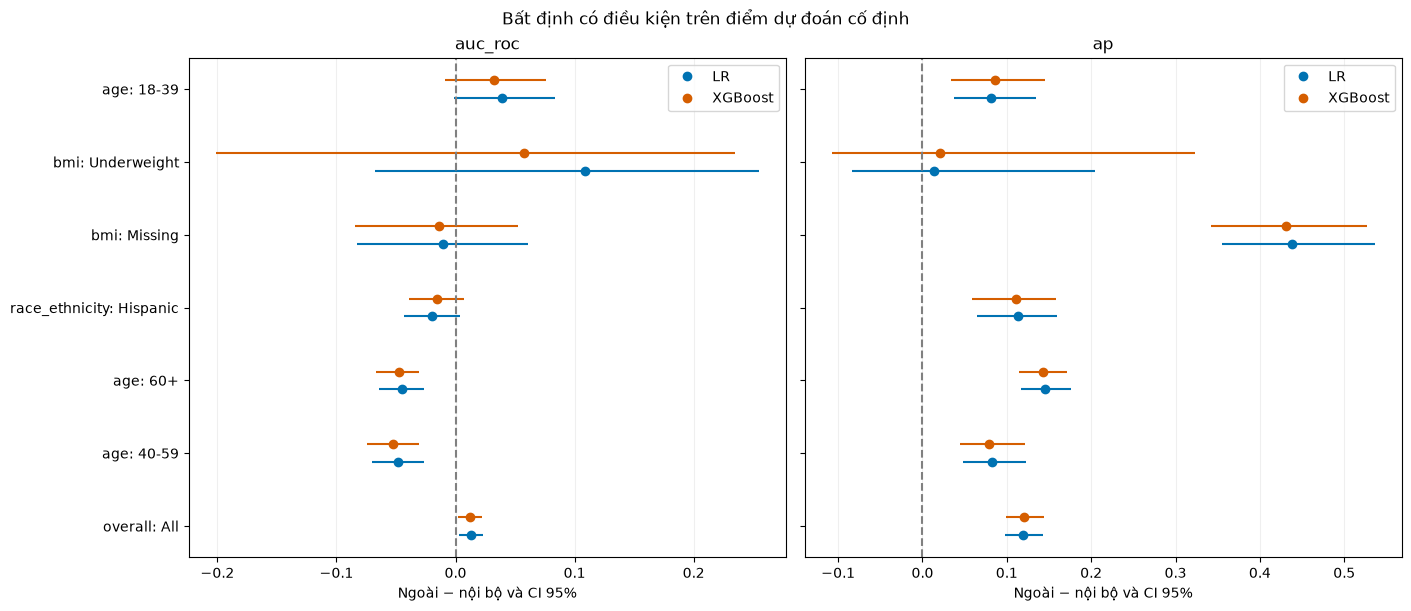

In [3]:
shift_delta = shift_ci['external_internal_delta_ci']
shift_plot_groups = [('overall', 'All')] + SHIFT_PRIORITIES
shift_fig, shift_axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, constrained_layout=True)
for shift_ax, shift_metric in zip(shift_axes, ['auc_roc', 'ap']):
    for shift_offset, shift_model, shift_color in [(-.12, 'LR', '#0072B2'), (.12, 'XGBoost', '#D55E00')]:
        for shift_i, (shift_attribute, shift_group) in enumerate(shift_plot_groups):
            shift_row = shift_delta.loc[shift_delta['model'].eq(shift_model) & shift_delta['metric'].eq(shift_metric)
                                        & shift_delta['attribute'].eq(shift_attribute) & shift_delta['group'].eq(shift_group)].iloc[0]
            shift_y = shift_i + shift_offset
            if np.isfinite(shift_row['ci_low']) and np.isfinite(shift_row['ci_high']):
                shift_ax.hlines(shift_y, shift_row['ci_low'], shift_row['ci_high'], color=shift_color)
                shift_ax.plot(shift_row['estimate'], shift_y, 'o', color=shift_color,
                              label=shift_model if shift_i == 0 else None)
    shift_ax.axvline(0, linestyle='--', color='gray')
    shift_ax.set(yticks=np.arange(len(shift_plot_groups)),
                 yticklabels=[f'{a}: {g}' for a, g in shift_plot_groups],
                 xlabel='Ngoài − nội bộ và CI 95%', title=shift_metric)
    shift_ax.legend()
    shift_ax.grid(axis='x', alpha=.2)
shift_fig.suptitle('Bất định có điều kiện trên điểm dự đoán cố định')
shift_fig.savefig(shift_figures_dir / 'delta_ci_priority_groups.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 14 — Phân bố tám đầu vào và dữ liệu thiếu

So sánh toàn tập và từng nhóm trên đúng các quần thể kiểm định, không dùng mẫu tuning thay tập test. Tuổi/BMI: n quan sát, trung bình, SD, các phân vị, chênh trung bình chuẩn hóa, KS và khoảng cách Wasserstein. SMD = (trung bình ngoài − nội bộ)/√[(SD² nội bộ + SD² ngoài)/2]; Wasserstein ở đơn vị gốc (năm, kg/m²). Biến phân loại: tần suất/tỷ lệ từng mức và total variation = ½ tổng chênh tuyệt đối tỷ lệ. Missing được tính như một mức riêng cho biến phân loại; với số liên tục, khoảng cách chỉ dùng quan sát không thiếu và báo mức thiếu riêng.

Các số này mang tính mô tả, không áp ngưỡng tự động để kết luận bias hoặc nguyên nhân. Chỉ số của biến dùng để định nghĩa nhóm cũng được giữ để kiểm tra, nhưng phân bố trong nhóm bị giới hạn bởi chính ranh giới nhóm. Ví dụ, BMI trong nhóm Missing không có giá trị quan sát, nên khoảng cách giữ NA.

,dataset,attribute,group,n,fraction_of_cohort,n_positive,positive_rate
0,BRFSS_internal_test,overall,All,89844,1.0000,12088,0.134544
1,NHANES_external,overall,All,10832,1.0000,2274,0.209934
12,BRFSS_internal_test,race_ethnicity,Hispanic,7409,0.0825,1073,0.144824
13,NHANES_external,race_ethnicity,Hispanic,2961,0.2734,693,0.234043
18,BRFSS_internal_test,age,18-39,19819,0.2206,453,0.022857
19,NHANES_external,age,18-39,3720,0.3434,170,0.045699
20,BRFSS_internal_test,age,40-59,28322,0.3152,3231,0.114081
21,NHANES_external,age,40-59,3339,0.3083,684,0.204852
22,BRFSS_internal_test,age,60+,41703,0.4642,8404,0.20152
23,NHANES_external,age,60+,3773,0.3483,1420,0.376358


,attribute,group,feature,n_internal,n_external,delta_missing_rate,kind,ks_statistic,wasserstein,standardized_mean_difference,total_variation,status
0,overall,All,age,89844,10832,0.0000,numeric,0.1468,5.7422,-0.3206,NaN,ok
1,overall,All,sex,89844,10832,-0.0007,categorical,NaN,NaN,NaN,0.0400,ok
2,overall,All,race_ethnicity,89844,10832,-0.0194,categorical,NaN,NaN,NaN,0.4342,ok
3,overall,All,bmi,89844,10832,-0.0588,numeric,0.1044,1.4175,0.2077,NaN,ok
4,overall,All,smoking_status,89844,10832,-0.0405,categorical,NaN,NaN,NaN,0.0832,ok
5,overall,All,physical_activity,89844,10832,-0.1086,categorical,NaN,NaN,NaN,0.2266,ok
6,overall,All,heart_attack,89844,10832,0.0411,categorical,NaN,NaN,NaN,0.0411,ok
7,overall,All,stroke,89844,10832,0.0433,categorical,NaN,NaN,NaN,0.0433,ok
48,race_ethnicity,Hispanic,age,7409,2961,0.0000,numeric,0.0927,2.3302,0.1157,NaN,ok
49,race_ethnicity,Hispanic,sex,7409,2961,-0.0005,categorical,NaN,NaN,NaN,0.0107,ok


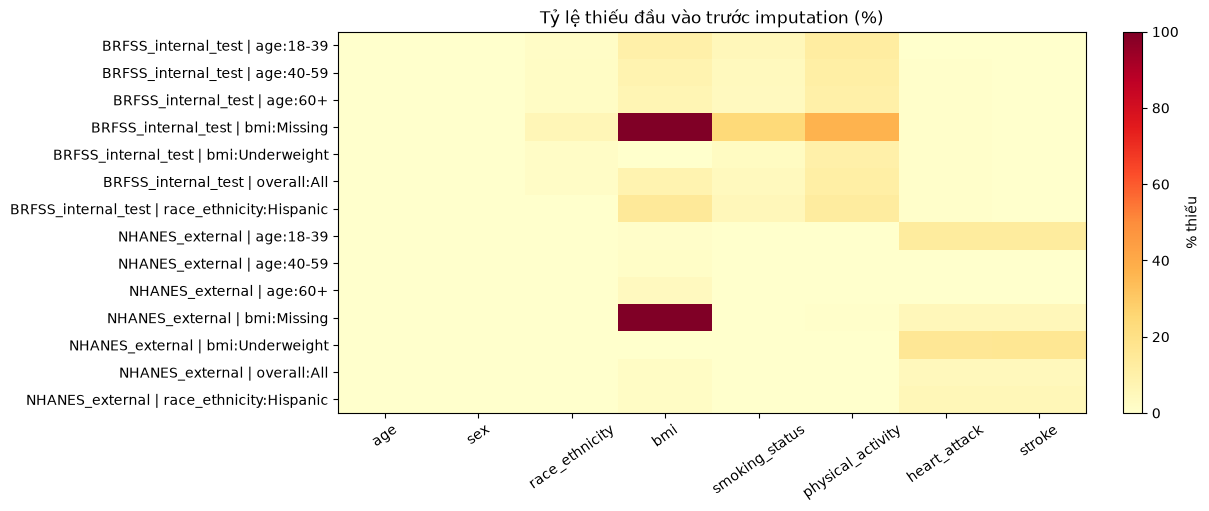

In [4]:
shift_distribution = shift_tools.distribution_tables(shift_bundle)
shift_tables.update(shift_distribution)
for shift_name, shift_table in shift_distribution.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
display(shift_distribution['group_composition'].loc[shift_focus(shift_distribution['group_composition'])].round(4))
display(shift_distribution['input_shift'].loc[shift_focus(shift_distribution['input_shift'])].round(4))
shift_missing = shift_distribution['missingness'].loc[shift_focus(shift_distribution['missingness'])].copy()
shift_missing['cohort_group'] = shift_missing['dataset'] + ' | ' + shift_missing['attribute'] + ':' + shift_missing['group']
shift_heat = shift_missing.pivot(index='cohort_group', columns='feature', values='missing_rate').reindex(columns=shift_tools.FEATURES)
shift_fig, shift_ax = plt.subplots(figsize=(12, max(5, len(shift_heat)*.35)), constrained_layout=True)
shift_image = shift_ax.imshow(np.ma.masked_invalid(shift_heat.to_numpy(float)*100), vmin=0, vmax=100, aspect='auto', cmap='YlOrRd')
shift_ax.set(xticks=np.arange(len(shift_heat.columns)), xticklabels=shift_heat.columns,
             yticks=np.arange(len(shift_heat)), yticklabels=shift_heat.index,
             title='Tỷ lệ thiếu đầu vào trước imputation (%)')
shift_ax.tick_params(axis='x', rotation=35)
shift_fig.colorbar(shift_image, ax=shift_ax, label='% thiếu')
shift_fig.savefig(shift_figures_dir / 'missingness_priority_groups.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

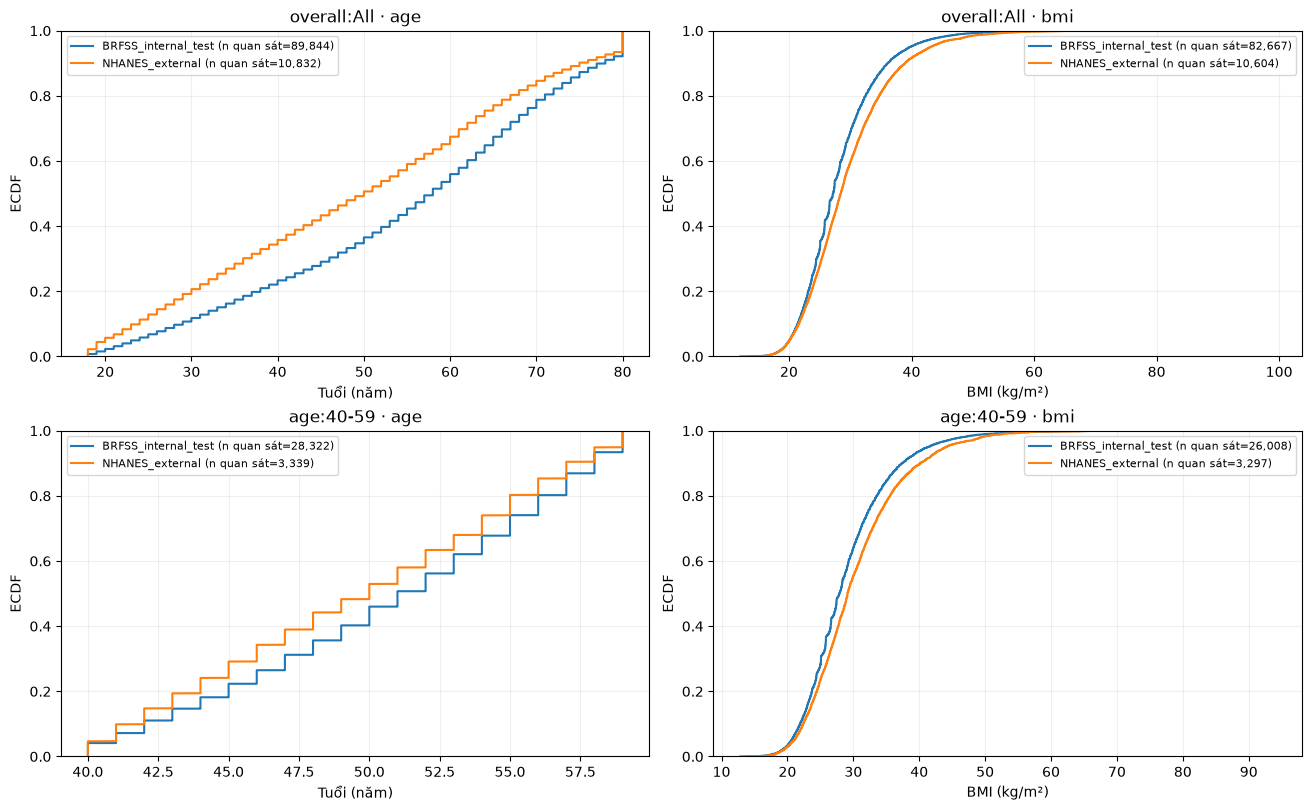

In [5]:
# ECDF toàn tập và trong một nhóm ưu tiên; đổi lựa chọn để xem nhóm khác.
SHIFT_DISTRIBUTION_GROUP = SHIFT_PRIORITIES[0]
shift_fig, shift_axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for shift_row, (shift_attribute, shift_group) in enumerate([('overall', 'All'), SHIFT_DISTRIBUTION_GROUP]):
    for shift_col, shift_feature in enumerate(['age', 'bmi']):
        shift_ax = shift_axes[shift_row, shift_col]
        for shift_dataset, shift_frame in shift_bundle['cohorts'].items():
            shift_mask = next(m for a, g, m in shift_tools.masks(shift_frame) if a == shift_attribute and g == shift_group)
            shift_values = np.sort(shift_frame.loc[shift_mask, shift_feature].dropna().to_numpy(dtype=float))
            if len(shift_values):
                shift_ax.step(shift_values, np.arange(1, len(shift_values)+1)/len(shift_values), where='post',
                              label=f'{shift_dataset} (n quan sát={len(shift_values):,})')
        shift_ax.set(title=f'{shift_attribute}:{shift_group} · {shift_feature}',
                     xlabel='Tuổi (năm)' if shift_feature == 'age' else 'BMI (kg/m²)', ylabel='ECDF', ylim=(0,1))
        shift_ax.legend(fontsize=8)
        shift_ax.grid(alpha=.2)
shift_fig.savefig(shift_figures_dir / 'numeric_ecdf.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 15 — Độ nhạy AP với tỷ lệ bệnh tham chiếu chung

Trong mỗi tập/nhóm, gán trọng số lớp dương `p_ref/n_positive`, lớp âm `(1−p_ref)/n_negative`, rồi gọi `average_precision_score(..., sample_weight=...)`. Như vậy mọi nhóm được đưa về cùng tỷ lệ dương tham chiếu; giữ nguyên điểm và thứ hạng, không lấy AP chia tỷ lệ bệnh. AUC không đổi dưới phép nhân trọng số hằng trong từng lớp này. mAP chuẩn hóa vẫn trung bình AP chuẩn hóa của các nhóm chính trong từng đặc trưng.

Đây chỉ là phân tích độ nhạy với tỷ lệ lớp, không sửa được khác biệt phân bố đặc trưng, chất lượng nhãn hoặc sai lệch đo lường. Không diễn giải AP chuẩn hóa là hiệu năng đã quan sát trên một quần thể mới. Nhóm thiếu một lớp giữ NA.

,dataset,model,attribute,group,n,n_positive,n_negative,observed_prevalence,reference_prevalence,ap_observed,ap_standardized,auc_roc,status
72,BRFSS_internal_test,LR,overall,All,89844,12088,77756,0.1345,0.15,0.3334,0.3609,0.7770,ok
78,BRFSS_internal_test,LR,race_ethnicity,Hispanic,7409,1073,6336,0.1448,0.15,0.3616,0.3709,0.7973,ok
81,BRFSS_internal_test,LR,age,18-39,19819,453,19366,0.0229,0.15,0.0818,0.3743,0.7339,ok
82,BRFSS_internal_test,LR,age,40-59,28322,3231,25091,0.1141,0.15,0.2849,0.3495,0.7500,ok
83,BRFSS_internal_test,LR,age,60+,41703,8404,33299,0.2015,0.15,0.3626,0.2871,0.7007,ok
85,BRFSS_internal_test,LR,bmi,Underweight,1445,73,1372,0.0505,0.15,0.1159,0.2890,0.6859,ok
89,BRFSS_internal_test,LR,bmi,Missing,7177,945,6232,0.1317,0.15,0.2676,0.2974,0.7317,ok
90,BRFSS_internal_test,XGBoost,overall,All,89844,12088,77756,0.1345,0.15,0.3521,0.3798,0.7854,ok
96,BRFSS_internal_test,XGBoost,race_ethnicity,Hispanic,7409,1073,6336,0.1448,0.15,0.3810,0.3904,0.8053,ok
99,BRFSS_internal_test,XGBoost,age,18-39,19819,453,19366,0.0229,0.15,0.0954,0.4001,0.7473,ok


,dataset,model,attribute,reference_prevalence,n_groups,n_groups_valid,map_observed,map_standardized
16,BRFSS_internal_test,LR,sex,0.15,2,2,0.3343,0.3611
17,BRFSS_internal_test,LR,race_ethnicity,0.15,4,4,0.3538,0.3530
18,BRFSS_internal_test,LR,age,0.15,3,3,0.2431,0.3370
19,BRFSS_internal_test,LR,bmi,0.15,3,3,0.2777,0.3153
20,BRFSS_internal_test,XGBoost,sex,0.15,2,2,0.3526,0.3796
21,BRFSS_internal_test,XGBoost,race_ethnicity,0.15,4,4,0.3735,0.3728
22,BRFSS_internal_test,XGBoost,age,0.15,3,3,0.2572,0.3549
23,BRFSS_internal_test,XGBoost,bmi,0.15,3,3,0.2949,0.3337
24,NHANES_external,LR,sex,0.15,2,2,0.4553,0.3598
25,NHANES_external,LR,race_ethnicity,0.15,4,4,0.4606,0.3647


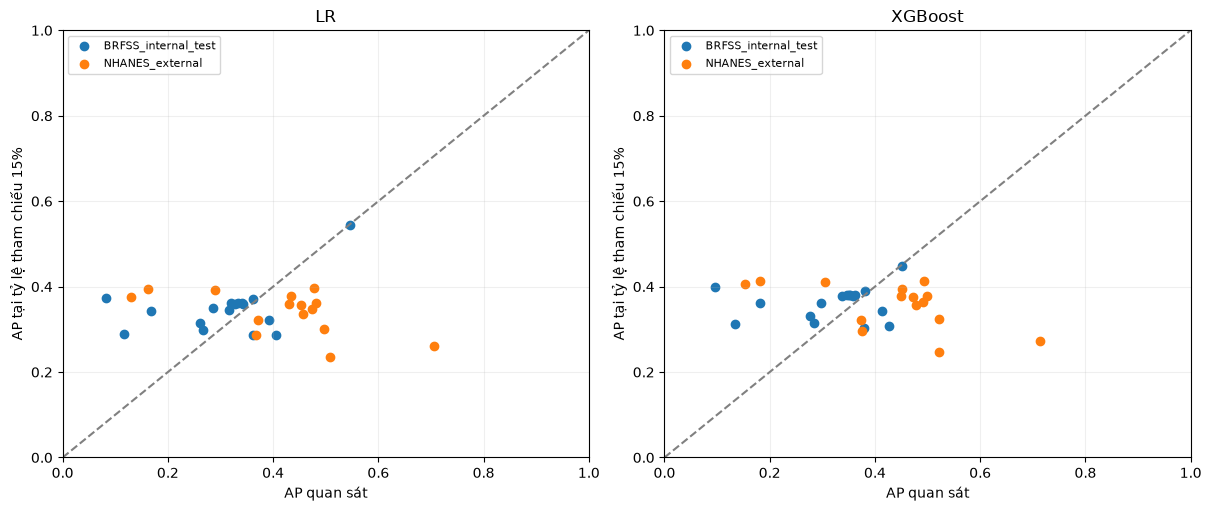

In [6]:
shift_sensitivity_parts, shift_macro_parts = [], []
for shift_prevalence in sorted(set(SHIFT_PREVALENCE_GRID + [SHIFT_REFERENCE_PREVALENCE])):
    shift_part = shift_tools.prevalence_sensitivity(shift_bundle, shift_prevalence)
    shift_sensitivity_parts.append(shift_part['prevalence_sensitivity'])
    shift_macro_parts.append(shift_part['prevalence_macro_ap'])
shift_tables['prevalence_sensitivity'] = pd.concat(shift_sensitivity_parts, ignore_index=True)
shift_tables['prevalence_macro_ap'] = pd.concat(shift_macro_parts, ignore_index=True)
for shift_name in ['prevalence_sensitivity', 'prevalence_macro_ap']:
    shift_tables[shift_name].to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
shift_prevalence_main = shift_tables['prevalence_sensitivity'].loc[
    np.isclose(shift_tables['prevalence_sensitivity']['reference_prevalence'], SHIFT_REFERENCE_PREVALENCE)]
display(shift_prevalence_main.loc[shift_focus(shift_prevalence_main)].round(4))
display(shift_tables['prevalence_macro_ap'].loc[
    np.isclose(shift_tables['prevalence_macro_ap']['reference_prevalence'], SHIFT_REFERENCE_PREVALENCE)].round(4))
shift_fig, shift_axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for shift_ax, shift_model in zip(shift_axes, shift_tools.MODELS):
    for shift_dataset in shift_bundle['cohorts']:
        shift_part = shift_prevalence_main.loc[shift_prevalence_main['model'].eq(shift_model)
                                              & shift_prevalence_main['dataset'].eq(shift_dataset)]
        shift_ax.scatter(shift_part['ap_observed'], shift_part['ap_standardized'], label=shift_dataset)
    shift_ax.plot([0,1], [0,1], '--', color='gray')
    shift_ax.set(title=shift_model, xlabel='AP quan sát', ylabel=f'AP tại tỷ lệ tham chiếu {SHIFT_REFERENCE_PREVALENCE:.0%}',
                 xlim=(0,1), ylim=(0,1))
    shift_ax.legend(fontsize=8)
    shift_ax.grid(alpha=.2)
shift_fig.savefig(shift_figures_dir / 'ap_prevalence_sensitivity.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 16 — Độ nhạy với nhãn chẩn đoán tự khai

Dữ liệu processed NHANES không giữ `DIQ010`; nối từ `data/raw/nhanes/2015-2016/DIQ_I.xpt` và `2017-2018/DIQ_J.xpt` bằng `SEQN × cycle`. Quy ước nhãn thay thế: `DIQ010=1` dương, `2/3` (không bệnh/borderline) âm, còn lại hoặc thiếu loại khỏi phân tích. BRFSS giữ nhãn đã dùng ở notebook 01 (`DIABETE3=1` dương, `2/3/4` âm).

Hai nguồn cùng gần khái niệm chẩn đoán tự khai hơn, **chưa được khẳng định tương đương hoàn toàn**. Đây là đánh giá lại ROC-AUC/AP của **điểm dự đoán cố định** với một định nghĩa đầu ra khác; không phải mô hình đã huấn luyện bằng nhãn mới, cũng không phải một quy trình dự báo mới được kiểm định độc lập. So sánh nhãn gốc và nhãn thay thế trên cùng tập người có câu trả lời hợp lệ; báo số bị loại và bảng chuyển nhãn để tránh nhầm ảnh hưởng của loại mẫu với đổi nhãn. Nếu thiếu file gốc, xuất trạng thái chưa đủ nguồn thay vì suy diễn nhãn.

In [7]:
shift_label_tables, shift_label_paths = shift_tools.self_report_sensitivity(shift_bundle, shift_project)
shift_tables.update(shift_label_tables)
for shift_name, shift_table in shift_label_tables.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
if 'label_sensitivity_status' in shift_label_tables:
    display(shift_label_tables['label_sensitivity_status'])
else:
    display(shift_label_tables['label_coverage'])
    display(shift_label_tables['label_transition'])
    shift_label_results = shift_label_tables['label_sensitivity']
    display(shift_label_results.loc[shift_focus(shift_label_results)].round(4))

,dataset,n_original,n_included,n_excluded_unknown_self_report,n_label_changed
0,BRFSS_internal_test,89844,89844,0,0
1,NHANES_external,10832,10830,2,549


,dataset,original_y,alternative_y,n
0,BRFSS_internal_test,0,0,77756
1,BRFSS_internal_test,1,1,12088
2,NHANES_external,0,0,8558
3,NHANES_external,1,0,549
4,NHANES_external,1,1,1723
5,NHANES_external,1,Excluded,2


,dataset,endpoint,model,attribute,group,n,n_positive,n_negative,positive_rate,auc_roc,ap,status
0,BRFSS_internal_test,original_on_common_subset,LR,overall,All,89844,12088,77756,0.1345,0.7770,0.3334,ok
6,BRFSS_internal_test,original_on_common_subset,LR,race_ethnicity,Hispanic,7409,1073,6336,0.1448,0.7973,0.3616,ok
9,BRFSS_internal_test,original_on_common_subset,LR,age,18-39,19819,453,19366,0.0229,0.7339,0.0818,ok
10,BRFSS_internal_test,original_on_common_subset,LR,age,40-59,28322,3231,25091,0.1141,0.7500,0.2849,ok
11,BRFSS_internal_test,original_on_common_subset,LR,age,60+,41703,8404,33299,0.2015,0.7007,0.3626,ok
13,BRFSS_internal_test,original_on_common_subset,LR,bmi,Underweight,1445,73,1372,0.0505,0.6859,0.1159,ok
17,BRFSS_internal_test,original_on_common_subset,LR,bmi,Missing,7177,945,6232,0.1317,0.7317,0.2676,ok
18,BRFSS_internal_test,self_report,LR,overall,All,89844,12088,77756,0.1345,0.7770,0.3334,ok
24,BRFSS_internal_test,self_report,LR,race_ethnicity,Hispanic,7409,1073,6336,0.1448,0.7973,0.3616,ok
27,BRFSS_internal_test,self_report,LR,age,18-39,19819,453,19366,0.0229,0.7339,0.0818,ok


## Bước 17 — Lưu nguồn và cách kết luận phần bổ sung

Đọc kết quả theo thứ tự: (1) ước lượng và CI của AUC/AP, đặc biệt nhóm ít ca bệnh; (2) CI của chênh lệch ngoài − nội bộ; (3) phân bố đầu vào và thiếu dữ liệu trong các nhóm đó; (4) AP khi cùng tỷ lệ tham chiếu; (5) kết quả với nhãn tự khai trên cùng tập người. Không dùng việc hai CI riêng lẻ chồng lấp hay không để thay cho CI chênh lệch.

Mức thiếu hoặc phân bố khác nhau là bằng chứng mô tả về chuyển dịch đầu vào, chưa chứng minh đó là nguyên nhân làm AUC giảm. Nếu chênh AP thay đổi khi chuẩn hóa tỷ lệ bệnh, chỉ kết luận kết quả AP nhạy với kịch bản tỷ lệ bệnh. Nếu đổi nhãn làm metric thay đổi, chỉ kết luận nhạy với định nghĩa đầu ra trên điểm dự đoán đã lưu. Chưa có biện pháp khắc phục nào được huấn luyện/thử trong phần bổ sung.

**Tài liệu phương pháp:** [scikit-learn average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) mô tả AP và `sample_weight`; [SciPy bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) mô tả lấy mẫu có hoàn lại, percentile CI và lấy mẫu ghép cặp. Tính percentile được triển khai với thứ tự điểm có ties giữ nguyên để giảm chi phí; các phép tính đã được đối chiếu bằng kiểm thử với scikit-learn. Định nghĩa nhãn thay thế là quy ước độ nhạy đã nêu rõ, không lấy từ hai trang tài liệu metric.

In [8]:
for shift_filename, shift_digest in shift_source_hashes.items():
    assert shift_tools.file_hash(shift_project / shift_filename) == shift_digest, shift_filename
shift_manifest = {
    'analysis_id': shift_id, 'config': shift_config,
    'frozen_scores': True, 'models_refitted': False, 'threshold_used': False,
    'ci_scope': 'fixed-score IID person-level approximation; not retraining or survey-design uncertainty',
    'label_scope': 'frozen-score endpoint sensitivity, original and alternative labels on common subset',
    'output_sha256': {str(p.relative_to(shift_dir)): shift_tools.file_hash(p)
                      for p in shift_dir.rglob('*') if p.is_file() and p.name != 'manifest.json'},
}
(shift_dir / 'manifest.json').write_text(json.dumps(shift_manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('Hoàn tất phân tích bổ sung:', shift_dir)
display(pd.DataFrame([{'table': name, 'rows': len(table)} for name, table in shift_tables.items()]))

Hoàn tất phân tích bổ sung: D:\nckh\diabetes-ml-fairness\diabetes-project\results\brfss_to_nhanes\holdout_validation\79dce7d27030baa2\research_checks\3068e6735ab22885


,table,rows
0,metric_ci,144
1,external_internal_delta_ci,72
2,paired_model_delta_ci,72
3,numeric_summary,72
4,categorical_distribution,658
5,input_shift,144
6,missingness,288
7,group_composition,36
8,prevalence_sensitivity,216
9,prevalence_macro_ap,48


### Nhận xét kết quả phần bổ sung đã chạy

Nguồn: analysis `3068e6735ab22885`, 1.000 bootstrap, CI 95%, các CSV và manifest trong [3068e6735ab22885](../results/brfss_to_nhanes/holdout_validation/79dce7d27030baa2/research_checks/3068e6735ab22885). Đây là kết quả trên điểm dự đoán cố định, không huấn luyện lại. CI là khoảng theo từng phép so sánh, không hiệu chỉnh đa so sánh hoặc thiết kế khảo sát; giới hạn OOF của 07 vẫn áp dụng.

**1. Bất định tổng thể.**

| Tập kiểm định | Mô hình | Metric | Ước lượng | CI 95% |
| --- | --- | --- | --- | --- |
| BRFSS_internal_test | LR | auc_roc | 0.7770 | [0.7730; 0.7810] |
| BRFSS_internal_test | LR | ap | 0.3334 | [0.3254; 0.3412] |
| BRFSS_internal_test | XGBoost | auc_roc | 0.7854 | [0.7815; 0.7895] |
| BRFSS_internal_test | XGBoost | ap | 0.3521 | [0.3437; 0.3605] |
| NHANES_external | LR | auc_roc | 0.7899 | [0.7804; 0.7993] |
| NHANES_external | LR | ap | 0.4530 | [0.4319; 0.4744] |
| NHANES_external | XGBoost | auc_roc | 0.7976 | [0.7881; 0.8073] |
| NHANES_external | XGBoost | ap | 0.4720 | [0.4513; 0.4953] |

So sánh mô hình dùng lấy mẫu người ghép cặp: BRFSS_internal_test: Δ AUC XGBoost−LR=0.0084, CI [0.0071; 0.0096]; NHANES_external: Δ AUC XGBoost−LR=0.0077, CI [0.0048; 0.0106]. Các CI trên chỉ được diễn giải trong phạm vi bootstrap có điều kiện đã nêu.

**2. Nhóm ưu tiên và chênh lệch AUC.**

| Mô hình | Đặc trưng | Nhóm | Δ AUC ngoài − nội bộ | CI 95% | n dương nội bộ/ngoài |
| --- | --- | --- | --- | --- | --- |
| LR | race_ethnicity | Hispanic | -0.0196 | [-0.0430; 0.0042] | 1073/693 |
| XGBoost | race_ethnicity | Hispanic | -0.0154 | [-0.0386; 0.0074] | 1073/693 |
| LR | age | 18-39 | 0.0390 | [-0.0012; 0.0838] | 453/170 |
| XGBoost | age | 18-39 | 0.0327 | [-0.0092; 0.0763] | 453/170 |
| LR | age | 40-59 | -0.0480 | [-0.0702; -0.0266] | 3231/684 |
| XGBoost | age | 40-59 | -0.0522 | [-0.0747; -0.0311] | 3231/684 |
| LR | age | 60+ | -0.0445 | [-0.0640; -0.0265] | 8404/1420 |
| XGBoost | age | 60+ | -0.0475 | [-0.0667; -0.0305] | 8404/1420 |
| LR | bmi | Underweight | 0.1085 | [-0.0680; 0.2545] | 73/7 |
| XGBoost | bmi | Underweight | 0.0574 | [-0.2013; 0.2350] | 73/7 |
| LR | bmi | Missing | -0.0105 | [-0.0825; 0.0608] | 945/126 |
| XGBoost | bmi | Missing | -0.0140 | [-0.0847; 0.0526] | 945/126 |

Các CI AUC của chênh lệch nằm hoàn toàn dưới 0 trong danh sách ưu tiên: LR age/40-59; XGBoost age/40-59; LR age/60+; XGBoost age/60+. Đây là dấu hiệu suy giảm trong phân tích bootstrap này, chưa phải bằng chứng về nguyên nhân hoặc suy luận dân số. CI chứa 0 không chứng minh hai hiệu năng tương đương. Cỡ nhóm và số ca ít, đặc biệt Underweight, cần đọc kèm `metric_ci.csv` và số bootstrap hợp lệ; không dùng chỉ độ rộng CI để lựa chọn lại mô hình.

**3. Chuyển dịch đầu vào và dữ liệu thiếu.** Ở toàn tập, age: SMD=-0.3206, KS=0.1468, Wasserstein=5.7422; bmi: SMD=0.2077, KS=0.1044, Wasserstein=1.4175. Các biến phân loại có TVD lớn nhất trong sáu biến được kiểm tra: race_ethnicity: TVD=0.4342; physical_activity: TVD=0.2266; smoking_status: TVD=0.0832. Wasserstein ở đơn vị gốc, SMD và KS có ý nghĩa khác nhau nên không gộp chúng thành một thứ hạng chung.

| Biến | Tỷ lệ thiếu nội bộ | Tỷ lệ thiếu ngoài |
| --- | --- | --- |
| bmi | 0.0799 | 0.0210 |
| race_ethnicity | 0.0194 | 0.0000 |
| sex | 0.0007 | 0.0000 |

Các tỷ lệ thiếu trên ở thang 0–1. Bảng `input_shift.csv` và hình mức thiếu cung cấp kết quả riêng cho nhóm ưu tiên. Chúng mô tả chuyển dịch đầu vào; chưa xác định yếu tố nào gây thay đổi AUC/AP.

**4. Độ nhạy với tỷ lệ bệnh chung.**

| Tập kiểm định | Mô hình | AP quan sát | AP tại tỷ lệ bệnh 15% |
| --- | --- | --- | --- |
| BRFSS_internal_test | LR | 0.3334 | 0.3609 |
| BRFSS_internal_test | XGBoost | 0.3521 | 0.3798 |
| NHANES_external | LR | 0.4530 | 0.3577 |
| NHANES_external | XGBoost | 0.4720 | 0.3764 |

Ở chiều BRFSS → NHANES, AP quan sát ngoài cao hơn nội bộ, nhưng khi cùng tỷ lệ tham chiếu 15%, AP ngoài hơi thấp hơn nội bộ ở cả hai mô hình. Thứ tự hai tập thay đổi dưới kịch bản chuẩn hóa, cho thấy kết luận dựa trên AP quan sát nhạy với tỷ lệ bệnh. Không diễn giải đây là tỷ phần chênh lệch do tỷ lệ bệnh gây ra hoặc bằng chứng đã loại bỏ bias. Các kịch bản 10% và 20% nằm trong `prevalence_sensitivity.csv`; mAP tương ứng nằm trong `prevalence_macro_ap.csv`.

**5. Độ nhạy với định nghĩa nhãn.** NHANES còn 10.830 người có câu trả lời tự khai hợp lệ (loại 2 người); 549 người đổi từ nhãn dương gốc sang nhãn âm tự khai. Nhãn gốc trên chính 10.830 người có 2.272 ca, nhãn tự khai có 1.723 ca. BRFSS giữ nguyên nhãn và tập người.

| Tập kiểm định | Mô hình | Định nghĩa nhãn trên cùng người | n | n dương | AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| BRFSS_internal_test | LR | original_on_common_subset | 89844 | 12088 | 0.7770 | 0.3334 |
| BRFSS_internal_test | LR | self_report | 89844 | 12088 | 0.7770 | 0.3334 |
| BRFSS_internal_test | XGBoost | original_on_common_subset | 89844 | 12088 | 0.7854 | 0.3521 |
| BRFSS_internal_test | XGBoost | self_report | 89844 | 12088 | 0.7854 | 0.3521 |
| NHANES_external | LR | original_on_common_subset | 10830 | 2272 | 0.7898 | 0.4527 |
| NHANES_external | LR | self_report | 10830 | 1723 | 0.7862 | 0.3718 |
| NHANES_external | XGBoost | original_on_common_subset | 10830 | 2272 | 0.7975 | 0.4716 |
| NHANES_external | XGBoost | self_report | 10830 | 1723 | 0.7974 | 0.3978 |

So sánh hai nhãn trên cùng người cho thấy metric nhạy với định nghĩa đầu ra, đặc biệt AP; không nhầm thay đổi này với ảnh hưởng chỉ do loại hai người hoặc với hiệu quả của một mô hình mới. Các điểm dự đoán vẫn được học cho nhãn ban đầu; nhãn tự khai hai nguồn chưa được chứng minh tương đương hoàn toàn. Phần bổ sung chưa thử biện pháp khắc phục hoặc xác định quan hệ nhân quả.
